## Images and cellular automata

A grayscale image is just a matrix, one value per pixel, and `imagesc` shows it with its values scaled to the colormap. Here is one built from `meshgrid` coordinates: a disk, a bar, and a gentle gradient behind them.

120 by 120 pixels, values from 0.05 to 1.00


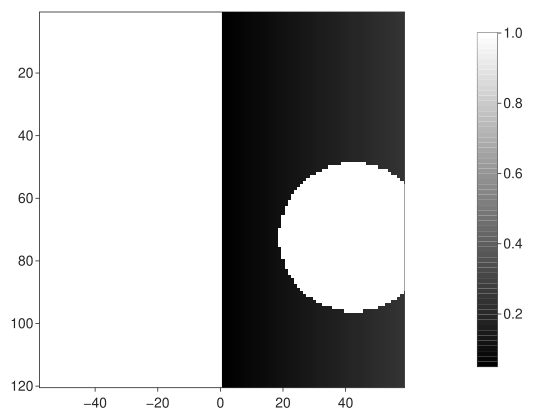

In [ ]:
[X, Y] = meshgrid(linspace(-1, 1, 120));
img = 0.25 + 0.2*X;
img((X + 0.3).^2 + (Y - 0.2).^2 < 0.16) = 1;
img(abs(X - 0.45) < 0.12 & abs(Y + 0.1) < 0.6) = 0.05;
figure
imagesc(img), colormap(gray), axis image, colorbar
fprintf('%d by %d pixels, values from %.2f to %.2f\n', size(img), min(img(:)), max(img(:)))

### Filtering with `conv2`

A filter slides a small kernel over the image and replaces each pixel by the weighted sum around it. A Gaussian kernel blurs; the Sobel kernels measure the change across and down, and the length of that gradient marks the edges.

the kernel sums to 1; strongest edge 3.99


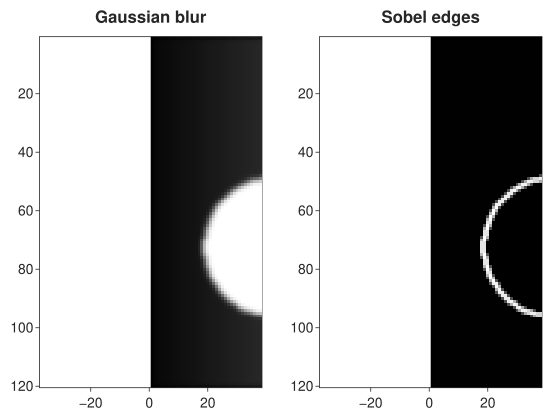

In [ ]:
[u, v] = meshgrid(-3:3);
G = exp(-(u.^2 + v.^2)/2); G = G / sum(G(:));
blurred = conv2(img, G, 'same');
sx = [-1 0 1; -2 0 2; -1 0 1];
gx = conv2(img, sx, 'same'); gy = conv2(img, sx', 'same');
edges = hypot(gx, gy);
edges([1 end], :) = 0; edges(:, [1 end]) = 0;   % the zero padding outside the image is not an edge
figure
subplot(1, 2, 1), imagesc(blurred), axis image, title('Gaussian blur')
subplot(1, 2, 2), imagesc(edges), axis image, title('Sobel edges')
colormap(gray)
fprintf('the kernel sums to %.15g; strongest edge %.2f\n', sum(G(:)), max(edges(:)))

### The Game of Life

Conway's rules on a grid of live (1) and dead (0) cells: a live cell with two or three live neighbors survives, a dead cell with exactly three comes alive, and every other cell dies or stays dead. `conv2` with a ring of ones counts every cell's neighbors at once.

live cells: 1051 at the start, 237 after 150 generations


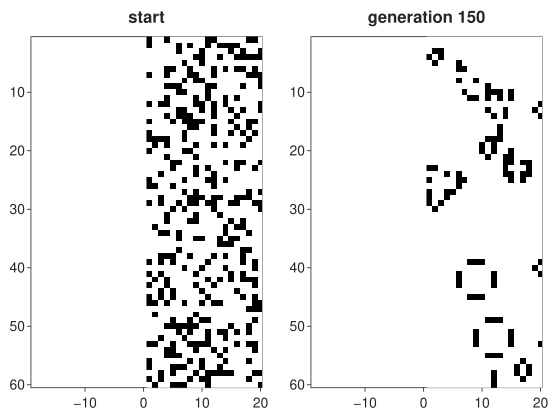

In [ ]:
rng(11)
A = double(rand(60) < 0.3);
ring = [1 1 1; 1 0 1; 1 1 1];
alive = zeros(1, 151); alive(1) = nnz(A);
snap = {A};
for g = 1:150
    N = conv2(A, ring, 'same');
    A = double(N == 3 | (A == 1 & N == 2));
    alive(g + 1) = nnz(A);
    if g == 150, snap{2} = A; end
end
figure
subplot(1, 2, 1), imagesc(snap{1}), axis image, title('start')
subplot(1, 2, 2), imagesc(snap{2}), axis image, title('generation 150')
colormap(flipud(gray))
fprintf('live cells: %d at the start, %d after 150 generations\n', alive(1), alive(end))

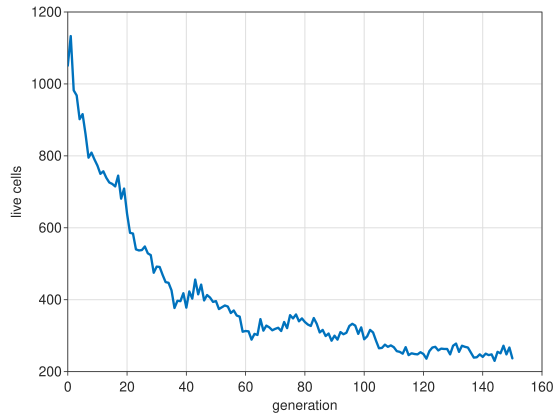

In [ ]:
figure
plot(0:150, alive, 'LineWidth', 1.2), grid on
xlabel('generation'), ylabel('live cells')

A glider is a pattern of five cells that moves one cell diagonally every four generations. `circshift` would wrap it around the edges; here it simply travels.

In [ ]:
A = zeros(12); A(2, 3) = 1; A(3, 4) = 1; A(4, 2:4) = 1;
[r0, c0] = find(A);
for g = 1:4
    N = conv2(A, ring, 'same');
    A = double(N == 3 | (A == 1 & N == 2));
end
[r1, c1] = find(A);
fprintf('after 4 generations the glider moved by (%d, %d)\n', min(r1) - min(r0), min(c1) - min(c0))

after 4 generations the glider moved by (1, 1)


### A one-dimensional automaton: rule 30

Each cell's next state depends on itself and its two neighbors, eight possible patterns; the rule's number written in binary gives the new state for each. Rows of the image are successive generations, starting from one live cell.

the center column starts 11011100110001011001


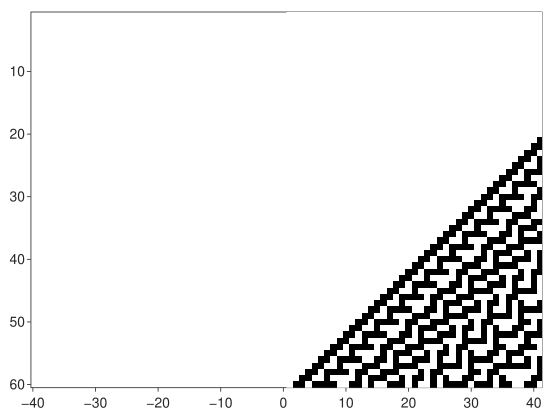

In [ ]:
rule = fliplr(dec2bin(30, 8) - '0');   % the new state for the patterns 0 to 7
w = 121; steps = 60;
R = zeros(steps, w); R(1, (w + 1)/2) = 1;
for k = 2:steps
    left = [0 R(k - 1, 1:end - 1)]; mid = R(k - 1, :); right = [R(k - 1, 2:end) 0];
    R(k, :) = rule(4*left + 2*mid + right + 1);
end
figure
imagesc(R), colormap(flipud(gray)), axis image
fprintf('the center column starts %s\n', sprintf('%d', R(1:20, (w + 1)/2)))

*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*